<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AMLEXP15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
`import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mobile Price dataset
mobile_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/refined_mobile_price.csv")

print("Mobile price class distribution:")
print(mobile_df["price_range"].value_counts(normalize=True)
      .mul(100).round(2))

# Marketing dataset
marketing_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AML/marketing_campaign_cleaned.csv")
target_marketing = "Response"

print("\nMarketing response distribution:")
print(marketing_df[target_marketing].value_counts(normalize=True)
      .mul(100).round(2))


Mobile price class distribution:
price_range
1.0    26.20
3.0    24.75
0.0    24.70
2.0    24.35
Name: proportion, dtype: float64

Marketing response distribution:
Response
0    85.09
1    14.91
Name: proportion, dtype: float64


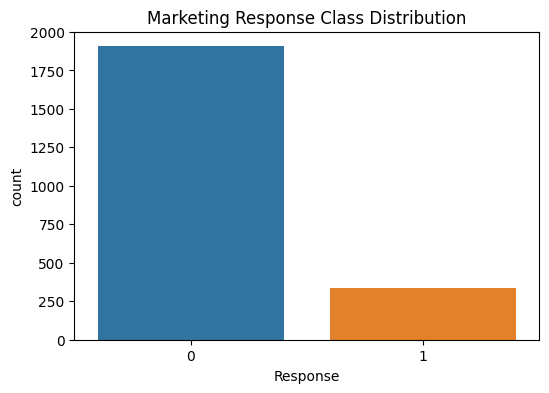

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(
    data=marketing_df,
    x=target_marketing,
    hue=target_marketing,
    legend=False
)
plt.title("Marketing Response Class Distribution")
plt.show()


In [ ]:
!pip install imbalanced-learn


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
X = marketing_df.drop(columns=[target_marketing])
X = pd.get_dummies(X, drop_first=True)
y = marketing_df[target_marketing]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

# These require X_train and X_test to be defined beforehand:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_balanced.value_counts().to_dict())


Before SMOTE: {0: 1527, 1: 265}
After SMOTE: {0: 1527, 1: 1527}


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model directly since 'models' is not defined
model = RandomForestClassifier(random_state=42)

# Fit on scaled training data
model.fit(X_train_scaled, y_train)

# Predict using scaled training and testing data
train_prediction = model.predict(X_train_scaled)
test_prediction = model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, train_prediction)
test_accuracy = accuracy_score(y_test, test_prediction)

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)
print("Accuracy gap:", train_accuracy - test_accuracy)

Training accuracy: 1.0
Testing accuracy: 0.8638392857142857
Accuracy gap: 0.1361607142857143


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest Classifier directly since 'models' is not defined
classification_model = RandomForestClassifier(random_state=42)

# Fit on the training data
classification_model.fit(X_train, y_train)

# Generate predictions
train_prediction = classification_model.predict(X_train)
test_prediction = classification_model.predict(X_test)

# Evaluate with appropriate classification metrics
print("Training Accuracy:", accuracy_score(y_train, train_prediction))
print("Testing Accuracy:", accuracy_score(y_test, test_prediction))
print("\nClassification Report:")
print(classification_report(y_test, test_prediction))

Training Accuracy: 1.0
Testing Accuracy: 0.8638392857142857

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.98      0.92       379
           1       0.67      0.23      0.34        69

    accuracy                           0.86       448
   macro avg       0.77      0.61      0.63       448
weighted avg       0.84      0.86      0.83       448



In [ ]:
from sklearn.ensemble import RandomForestClassifier

regularized_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced"
)


In [ ]:
# Compare marketing response by selected categorical variables
for column in ["Education", "Marital_Status", "Country", "Gender"]:
    if column in marketing_df.columns:
        print(f"\nResponse rate by {column}:")
        print(
            marketing_df.groupby(column)[target_marketing]
            .mean()
            .sort_values(ascending=False)
        )



Response rate by Education:
Education
PhD           0.207819
Master        0.154054
Graduation    0.134871
2n Cycle      0.108374
Basic         0.037037
Name: Response, dtype: float64

Response rate by Marital_Status:
Marital_Status
Absurd      0.500000
YOLO        0.500000
Alone       0.333333
Widow       0.246753
Single      0.220833
Divorced    0.206897
Married     0.113426
Together    0.103448
Name: Response, dtype: float64


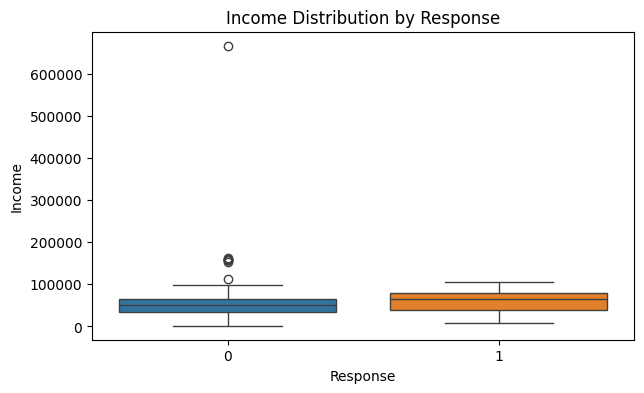

In [ ]:
for column in ["Income", "Age", "TotalSpending"]:
    if column in marketing_df.columns:
        plt.figure(figsize=(7, 4))
        sns.boxplot(
            data=marketing_df,
            x=target_marketing,
            y=column,
            hue=target_marketing,
            legend=False
        )
        plt.title(f"{column} Distribution by Response")
        plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    models["Random Forest"],
    X,
    y,
    cv=cv,
    scoring="f1_weighted"
)

print("Cross-validation scores:", cv_scores)
print("Mean F1-score:", cv_scores.mean())


Cross-validation scores: [0.84961822 0.83824213 0.85690525 0.81947873 0.84684783]
Mean F1-score: 0.84221843058254
